In [ ]:
import sys
sys.path.append("../..")
import importlib
import clean_data

importlib.reload(clean_data)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier, Pool 

from sklearn.metrics import classification_report, log_loss, f1_score, balanced_accuracy_score

from clean_data import feature_engineering_days

In [7]:
df = pd.read_csv("../../data/austin/raw/aac_intakes.csv")
outcomes = pd.read_csv("../../data/austin/raw/aac_intakes_outcomes.csv")

df["datetime"] = pd.to_datetime(df["datetime"])
outcomes["intake_datetime"] = pd.to_datetime(outcomes["intake_datetime"])

df = df.merge(
    outcomes[["animal_id_intake", "intake_datetime", "time_in_shelter_days"]],
    left_on=["animal_id", "datetime"],
    right_on=["animal_id_intake", "intake_datetime"],
    how="inner"
)

df = df[df["animal_type"] == "Dog"].copy()

In [8]:
df = feature_engineering_days(df)

df_dogs = df[df["animal_type"] == "Dog"].copy()
df_dogs = df_dogs.sort_values("intake_datetime").reset_index(drop=True)

bins = [-np.inf, 4, 10, np.inf]
df_dogs["target"] = pd.cut(
    df_dogs["time_in_shelter_days"], bins=bins, labels=[0, 1, 2]
).astype(int)

In [9]:
drop_cols = [
    "target", "time_in_shelter_days", "time_in_shelter", "intake_datetime", 
    "animal_type", "young_and_cat", "datetime"
]

X = df_dogs.drop(columns=drop_cols, errors="ignore")
y = df_dogs["target"]

#categorical features which will be available
cat_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
X[cat_features] = X[cat_features].fillna("Unknown").astype(str)

#70/15/15
n = len(X)
i1, i2 = int(n * 0.70), int(n * 0.85)

X_train, X_val, X_test = X.iloc[:i1], X.iloc[i1:i2], X.iloc[i2:]
y_train, y_val, y_test = y.iloc[:i1], y.iloc[i1:i2], y.iloc[i2:]

print("Split:", len(X_train), len(X_val), len(X_test))

Split: 31434 6736 6737


In [10]:
model = CatBoostClassifier(
    iterations=1200, learning_rate=0.03, depth=6,
    loss_function="MultiClass", random_seed=42, verbose=100
)

model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	learn: 1.0912634	test: 1.0905128	best: 1.0905128 (0)	total: 268ms	remaining: 5m 20s
100:	learn: 0.9230574	test: 0.9204256	best: 0.9204256 (100)	total: 12.3s	remaining: 2m 13s
200:	learn: 0.8957954	test: 0.9020895	best: 0.9020895 (200)	total: 22.4s	remaining: 1m 51s
300:	learn: 0.8817433	test: 0.8949517	best: 0.8949517 (300)	total: 32.6s	remaining: 1m 37s
400:	learn: 0.8700808	test: 0.8903606	best: 0.8903606 (400)	total: 42.9s	remaining: 1m 25s
500:	learn: 0.8607261	test: 0.8883919	best: 0.8883919 (500)	total: 54.5s	remaining: 1m 16s
600:	learn: 0.8531176	test: 0.8862668	best: 0.8862487 (597)	total: 1m 7s	remaining: 1m 6s
700:	learn: 0.8466226	test: 0.8843124	best: 0.8843124 (700)	total: 1m 18s	remaining: 56.1s
800:	learn: 0.8402528	test: 0.8837130	best: 0.8836886 (798)	total: 1m 28s	remaining: 44.2s
900:	learn: 0.8348150	test: 0.8832574	best: 0.8832574 (900)	total: 1m 39s	remaining: 32.9s
1000:	learn: 0.8287590	test: 0.8827329	best: 0.8827281 (999)	total: 1m 51s	remaining: 22.2s
110

CatBoostClassifier(depth=6, iterations=1200, learning_rate=0.03, loss_function='MultiClass', random_seed=42, verbose=100)

In [11]:
X_train.columns

Index(['breed', 'color', 'intake_condition', 'intake_type', 'name',
       'previous_intakes', 'is_repeat', 'intake_hour', 'month_sin',
       'month_cos', 'sex', 'intact', 'is_mixed_breed', 'primary_breed',
       'is_mixed_color', 'primary_color', 'has_name', 'name_length',
       'age_days', 'day_of_week', 'month', 'year', 'is_weekend', 'is_puppy',
       'is_senior', 'age_log', 'puppy_and_intact', 'stray_and_intact',
       'breed_age'],
      dtype='object')

# Evaluation


In [12]:
probs = model.predict_proba(X_test)
y_pred = model.classes_[np.argmax(probs, axis=1)]

#Log Loss
ll = log_loss(y_test, probs, labels=model.classes_)

#Multiclass Brier Score
y_onehot = (
    np.asarray(y_test)[:, None]
    == np.asarray(model.classes_)[None, :]
).astype(int)

brier = np.mean(np.sum((probs - y_onehot) ** 2, axis=1))

#Macro F1
f1 = f1_score(y_test, y_pred, average="macro")

#Balanced Accuracy
bal_acc = balanced_accuracy_score(y_test, y_pred)

print(f"Log Loss:          {ll:.4f}")
print(f"Brier Score:       {brier:.4f}")
print(f"Macro F1:          {f1:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Log Loss:          0.8791
Brier Score:       0.5252
Macro F1:          0.5859
Balanced Accuracy: 0.5854

Classification report:
              precision    recall  f1-score   support

           0       0.63      0.61      0.62      2466
           1       0.60      0.63      0.61      2583
           2       0.52      0.52      0.52      1688

    accuracy                           0.59      6737
   macro avg       0.59      0.59      0.59      6737
weighted avg       0.59      0.59      0.59      6737



In [13]:
from sklearn.metrics import precision_recall_curve, average_precision_score

classes = list(model.classes_)
i2 = classes.index(2)

p2_val = model.predict_proba(X_val)[:, i2]
p2_test = model.predict_proba(X_test)[:, i2]

# Wybór progu na walidacji: najwyższa precyzja przy recall >= 0.6
prec, rec, thr = precision_recall_curve((y_val == 2).astype(int), p2_val)
ok = rec[:-1] >= 0.8
threshold = thr[ok][np.argmax(prec[:-1][ok])]
print(f"Próg dla klasy >10 dni: {threshold:.3f}")

# Ocena na teście
flag = p2_test >= threshold
y_long = (y_test == 2).astype(int)
tp = np.sum(flag & (y_long == 1))
print(f"Oznaczone: {flag.mean():.1%} zwierząt")
print(f"Precyzja: {tp / max(flag.sum(), 1):.3f}")
print(f"Recall:   {tp / y_long.sum():.3f}")
print(f"PR-AUC (klasa >10): {average_precision_score(y_long, p2_test):.3f}")

Próg dla klasy >10 dni: 0.227
Oznaczone: 48.9% zwierząt
Precyzja: 0.412
Recall:   0.803
PR-AUC (klasa >10): 0.542


In [14]:
def predict_dog(model, dog):
    probs = model.predict_proba(dog)[0]

    return pd.DataFrame({
        "Czas pobytu": ["≤4 dni", "4–10 dni", ">10 dni"],
        "Prawdopodobieństwo (%)": [
            round(probs[list(model.classes_).index(i)] * 100, 2)
            for i in [0, 1, 2]
        ]
    })


In [15]:
dog = X_test.iloc[[0]]
print(df_dogs.loc[dog.index[0], "time_in_shelter_days"])
display(predict_dog(model, dog))

1.16875


,Czas pobytu,Prawdopodobieństwo (%)
0,≤4 dni,13.94
1,4–10 dni,78.65
2,>10 dni,7.41


In [16]:
dog = X_test.iloc[[30]]

print(df_dogs.loc[dog.index[0], "time_in_shelter_days"])

display(predict_dog(model, dog))

0.1284722222222222


,Czas pobytu,Prawdopodobieństwo (%)
0,≤4 dni,27.90
1,4–10 dni,61.65
2,>10 dni,10.45


In [17]:
long_stay = X_test[df_dogs.loc[X_test.index, "time_in_shelter_days"] > 60]

dog = long_stay.iloc[[0]]

print(df_dogs.loc[dog.index[0], "time_in_shelter_days"])
display(predict_dog(model, dog))


64.74027777777778


,Czas pobytu,Prawdopodobieństwo (%)
0,≤4 dni,24.84
1,4–10 dni,32.64
2,>10 dni,42.52


In [18]:
# import shap

# explainer = shap.TreeExplainer(model)
# X_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)
# shap_values = explainer(X_sample)

# print(shap_values.values.shape)

In [19]:
# class_idx = list(model.classes_).index(2)
# shap_long = shap_values[:, :, class_idx]
# shap.plots.beeswarm(shap_long, max_display=15)

In [20]:
# dog = X_test.iloc[[0]]
# display(predict_dog(model, dog))

# dog_shap = explainer(dog)

# shap.plots.waterfall(
#     dog_shap[0, :, class_idx],
#     max_display=15
# )

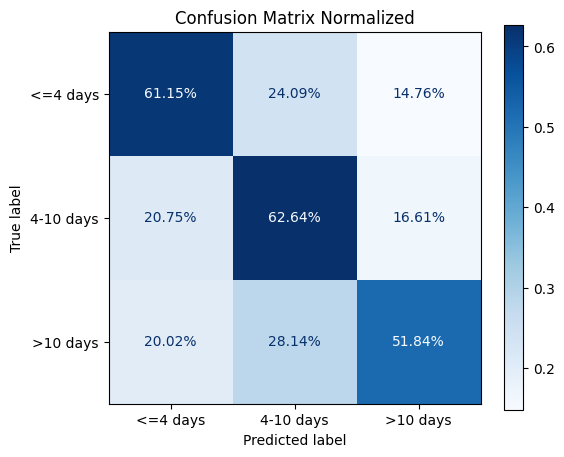

In [ ]:
# import matplotlib.pyplot as plt
# from sklearn.metrics import ConfusionMatrixDisplay

# fig, ax = plt.subplots(figsize=(6, 5))

# ConfusionMatrixDisplay.from_predictions(
#     y_true=y_test,
#     y_pred=y_pred,
#     display_labels=["<=4 days", "4-10 days", ">10 days"],
#     normalize="true",
#     values_format=".2%",
#     cmap="Blues",
#     ax=ax,
# )

# ax.set_title("Confusion Matrix Normalized")
# plt.grid(False)
# plt.show()

In [ ]:
# import pandas as pd
# from sklearn.metrics import mean_absolute_error

# df_old = pd.read_parquet("old_model_test_benchmark.parquet")

# days = df_dogs.loc[X_train.index, "time_in_shelter_days"]

# old_bins = pd.cut(days, bins=[-float("inf"), 7, 30, float("inf")], labels=[0, 1, 2])
# old_medians = days.groupby(old_bins, observed=False).median().tolist()

# new_bins = pd.cut(days, bins=[-float("inf"), 4, 10, float("inf")], labels=[0, 1, 2])
# new_medians = days.groupby(new_bins, observed=False).median().tolist()

# print(f"Stare mediany (reprezentanci klas): {[round(m, 2) for m in old_medians]}")
# print(f"Nowe mediany (reprezentanci klas):  {[round(m, 2) for m in new_medians]}")

# # Oczekiwana liczba dni
# # Stary model
# expected_old = (
#     df_old["prob_class_0"] * old_medians[0] +
#     df_old["prob_class_1"] * old_medians[1] +
#     df_old["prob_class_2"] * old_medians[2]
# )

# # Nowy model
# expected_new = (
#     probs[:, 0] * new_medians[0] +
#     probs[:, 1] * new_medians[1] +
#     probs[:, 2] * new_medians[2]
# )

# # Błąd względem rzeczywistości
# mae_old = mean_absolute_error(df_old["actual_days"], expected_old)
# mae_new = mean_absolute_error(df_old["actual_days"], expected_new)

# print(f"Średni błąd starego modelu: {mae_old:.2f} dni")
# print(f"Średni błąd nowego modelu:  {mae_new:.2f} dni")

Stare mediany (reprezentanci klas): [3.23, 11.18, 59.08]
Nowe mediany (reprezentanci klas):  [1.14, 5.3, 24.07]
Średni błąd starego modelu: 9.88 dni
Średni błąd nowego modelu:  9.01 dni


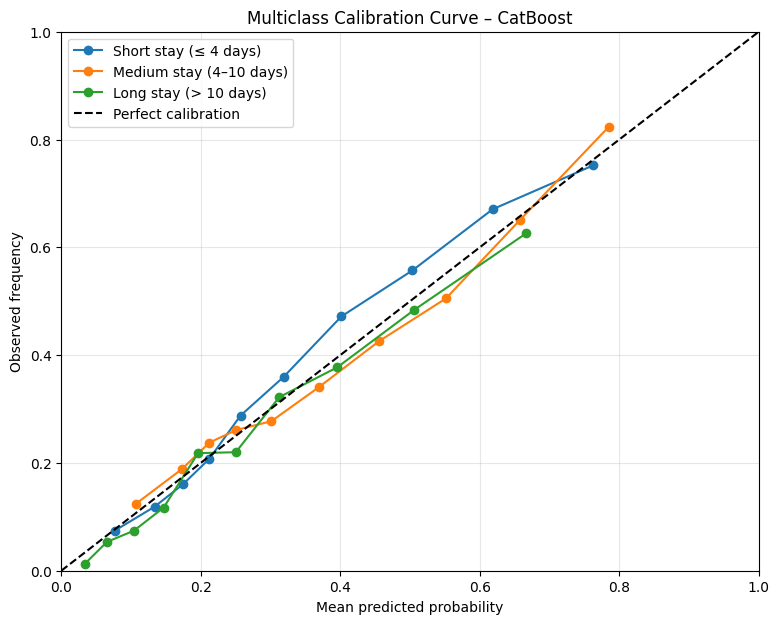

In [ ]:
# import matplotlib.pyplot as plt
# from sklearn.calibration import calibration_curve

# y_proba = model.predict_proba(X_test)

# class_names = [
#     "Short stay (≤ 4 days)",
#     "Medium stay (4–10 days)",
#     "Long stay (> 10 days)"
# ]

# plt.figure(figsize=(9, 7))

# for i, cls in enumerate(model.classes_):
#     prob_true, prob_pred = calibration_curve(
#         (y_test == cls).astype(int),
#         y_proba[:, i],
#         n_bins=10,
#         strategy="quantile"
#     )

#     plt.plot(
#         prob_pred,
#         prob_true,
#         marker="o",
#         label=class_names[i]
#     )

# plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

# plt.xlabel("Mean predicted probability")
# plt.ylabel("Observed frequency")
# plt.title("Multiclass Calibration Curve – CatBoost")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.xlim(0, 1)
# plt.ylim(0, 1)
# plt.show()